In [56]:
import numpy as np
import pandas as pd

In [57]:
df = pd.read_csv("placement.csv")

In [58]:
df.head()           

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [59]:
df.shape

(100, 4)

In [60]:
df = df.iloc[:,1:]

In [61]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


## Preprocessing, EDA and Feature Selection

In [62]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [63]:
df.isnull().sum()

cgpa         0
iq           0
placement    0
dtype: int64

In [64]:
df.duplicated().sum()

np.int64(0)

In [65]:
# or directly
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


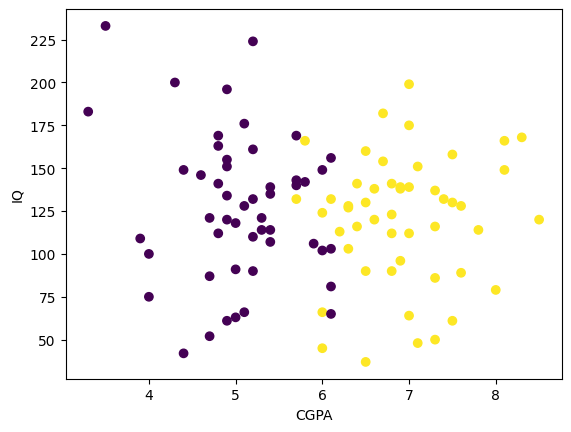

In [66]:
plt.scatter(df['cgpa'], df['iq'], c=df['placement'])
plt.xlabel("CGPA")
plt.ylabel("IQ")
plt.show()

In [67]:
X = df.iloc[:, 0:2]
y =df.iloc[:, -1]

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.1)

In [70]:
X_train.shape

(90, 2)

In [71]:
# generally we scale then split, but this is fine too for this study purpose, because scaled data won't show row numbers
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [72]:
X_train_scaled

array([[-0.90197812, -0.14386613],
       [-0.54903016,  0.27700419],
       [ 0.6862877 , -0.2924086 ],
       [-1.16668909, -0.0695949 ],
       [-0.28431919,  0.40078958],
       [-1.78434803, -0.58949353],
       [-1.43140007, -2.02540403],
       [ 0.15686576, -0.26765152],
       [-1.25492608,  0.54933205],
       [-0.01960822, -0.53997937],
       [ 0.06862877, -0.51522229],
       [ 0.24510275,  0.07894757],
       [ 1.12747265, -0.19338028],
       [-1.16668909, -0.91133554],
       [-0.54903016, -0.24289444],
       [ 0.77452469,  0.3760325 ],
       [-1.51963706,  1.88621424],
       [ 0.06862877,  0.20273296],
       [-0.63726715, -0.0695949 ],
       [-0.01960822,  0.62360328],
       [-0.28431919,  0.47506081],
       [-0.01960822, -1.9511328 ],
       [ 0.24510275,  0.10370465],
       [ 0.77452469,  0.35127542],
       [-0.28431919,  0.20273296],
       [ 1.30394664, -1.55501956],
       [ 1.83336858,  0.62360328],
       [-0.01960822,  0.00467634],
       [-0.1960822 ,

In [73]:
from sklearn.linear_model import LogisticRegression

In [74]:
clf = LogisticRegression()

In [75]:
# model training
clf.fit(X_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [76]:
y_pred = clf.predict(X_test_scaled)

In [77]:
y_test

55    1
40    0
78    0
51    0
38    1
21    1
75    0
28    0
45    1
31    0
Name: placement, dtype: int64

In [78]:
from sklearn.metrics import accuracy_score

In [79]:
accuracy_score(y_test, y_pred)

0.9